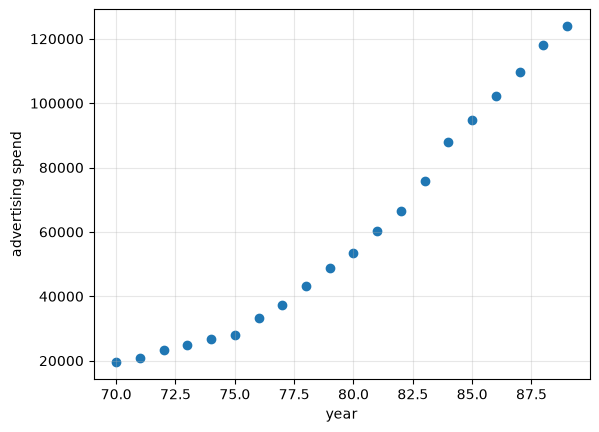

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

years = np.arange(70, 90, dtype=float)
advertising = np.array([19550, 20700, 23210, 24980, 26620, 27900, 33300,
                        37440, 43330, 48780, 53550, 60430, 66580, 75850,
                        87820, 94750, 102140, 109650, 118050, 123930],
                       dtype=float)

plt.scatter(years, advertising)
plt.xlabel("year")
plt.ylabel("advertising spend")
plt.grid(alpha=0.3)
plt.show()


[-401900.05263158    5809.15789474]
R^2 = 0.9531


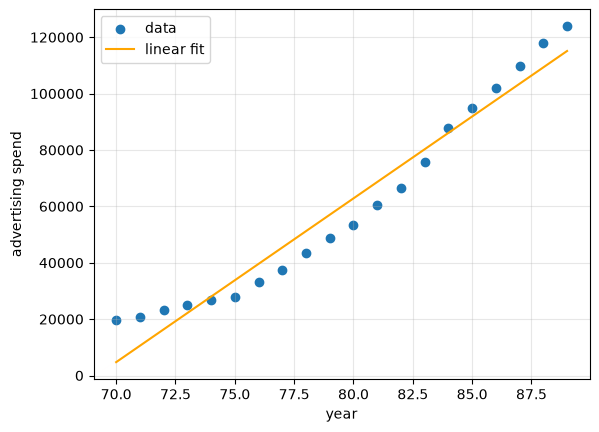

In [2]:
# Linear model: y = a + b year
X = sm.add_constant(years)
linear = sm.OLS(advertising, X).fit()
fit_linear = linear.predict(X)

print(linear.params)
print(f"R^2 = {linear.rsquared:.4f}")

plt.scatter(years, advertising, label="data")
plt.plot(years, fit_linear, color="orange", label="linear fit")
plt.xlabel("year")
plt.ylabel("advertising spend")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


[2.43693586 0.10548878]
R^2 (log scale) = 0.9935


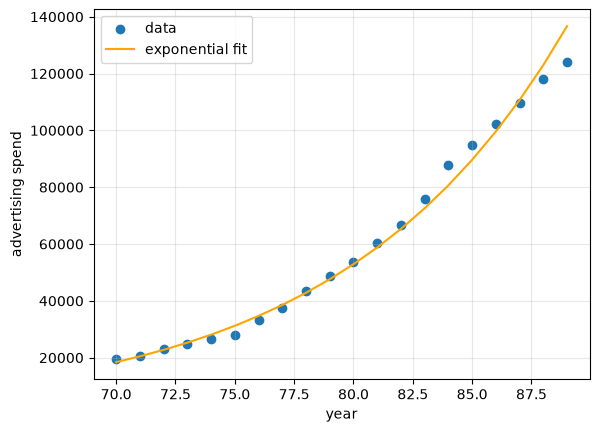

In [3]:
# Exponential model: log y = a + b year
log_advertising = np.log(advertising)
exponential = sm.OLS(log_advertising, X).fit()
fit_exponential = np.exp(exponential.predict(X))

print(exponential.params)
print(f"R^2 (log scale) = {exponential.rsquared:.4f}")

plt.scatter(years, advertising, label="data")
plt.plot(years, fit_exponential, color="orange", label="exponential fit")
plt.xlabel("year")
plt.ylabel("advertising spend")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


[-25.70936844   8.35392398]
R^2 (log-log scale) = 0.9931


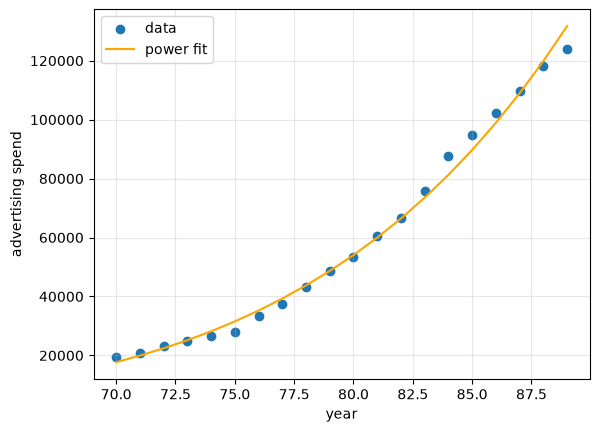

In [4]:
# Power model: log y = a + b log year
log_years = np.log(years)
X_log = sm.add_constant(log_years)
power = sm.OLS(log_advertising, X_log).fit()
fit_power = np.exp(power.predict(X_log))

print(power.params)
print(f"R^2 (log-log scale) = {power.rsquared:.4f}")

plt.scatter(years, advertising, label="data")
plt.plot(years, fit_power, color="orange", label="power fit")
plt.xlabel("year")
plt.ylabel("advertising spend")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


linear       RMSE =   7433.10
exponential  RMSE =   3918.77
power        RMSE =   2972.63


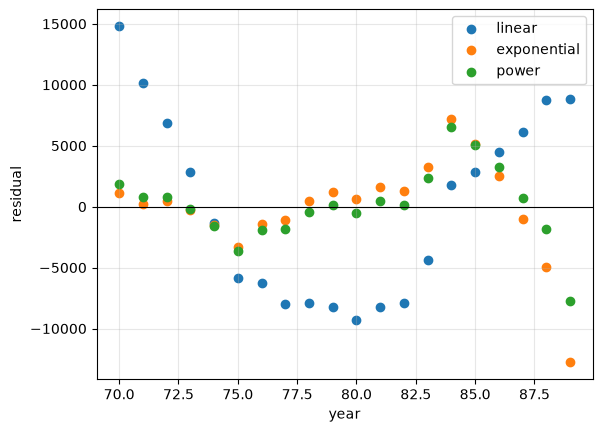

In [5]:
residuals = {
    "linear": advertising - fit_linear,
    "exponential": advertising - fit_exponential,
    "power": advertising - fit_power,
}
for name, residual in residuals.items():
    print(f"{name:12s} RMSE = {np.sqrt(np.mean(residual**2)):9.2f}")

plt.scatter(years, residuals["linear"], label="linear")
plt.scatter(years, residuals["exponential"], label="exponential")
plt.scatter(years, residuals["power"], label="power")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("year")
plt.ylabel("residual")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
